
# Insurance Claim Prediction Using Machine Learning

## 1. Project Overview

Insurance claim prediction is an application of machine learning that uses historical insurance data to identify patterns associated with claim outcomes.

This project analyzes an insurance dataset and develops machine learning models to predict the target outcome. The workflow includes data loading, data quality analysis, exploratory data analysis (EDA), data preprocessing, model training, performance evaluation, threshold tuning, and feature importance analysis.

Three classification algorithms are evaluated:

- Logistic Regression
- Random Forest
- Gradient Boosting

The models are compared using Accuracy, Precision, Recall, F1 Score, ROC-AUC, and Average Precision. These metrics help evaluate model performance on an imbalanced dataset.

## 2. Problem Statement

The main problem is to develop a machine learning model that can distinguish between observations belonging to the positive and negative target classes.

The project aims to:

1. Understand the structure and quality of the insurance dataset.
2. Analyze the distribution of the target variable and available features.
3. Prepare the data for machine learning.
4. Train and evaluate multiple classification models.
5. Compare model performance using appropriate evaluation metrics.
6. Investigate classification thresholds and feature importance.
7. Recommend a model for further validation and potential use.

## 3. Project Scope

This project focuses on insurance claim prediction using the supplied dataset. The results will be used to understand the strengths, weaknesses, and limitations of the tested machine learning models.

**Scope clarification:** The dataset supports prediction of an insurance claim-related target. It does not directly indicate whether a customer will purchase a new insurance policy.


In [1]:

# Step 1: Import required libraries
import os
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Download and extract the dataset

import urllib.request
import zipfile
import os

url = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1010-InsClaimPred.zip"

zip_path = "PRCP-1010-InsClaimPred.zip"
extract_dir = "insurance_data"

# Download the ZIP file
if not os.path.exists(zip_path):
    urllib.request.urlretrieve(url, zip_path)

print("Dataset downloaded successfully!")

# Create a folder for the extracted files
os.makedirs(extract_dir, exist_ok=True)

# Extract the ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extracted successfully!")

# Display the extracted file names
for root, dirs, files in os.walk(extract_dir):
    for file in files:
        print(os.path.join(root, file))


Dataset downloaded successfully!
Dataset extracted successfully!
insurance_data\Data\train.csv


## 4. Dataset Description

The dataset contains insurance-related records used to build a binary classification model.

The initial dataset inspection shows:

- **Total observations:** 595,212
- **Total columns:** 59
- **Target variable:** `target`
- **Identifier column:** `id`
- **Target classes:** 0 and 1

The target variable represents two different outcome classes. The distribution of these classes will be examined to understand whether the dataset is balanced or imbalanced.

The dataset will be inspected for missing values, data types, duplicate records, and feature distributions before model training.

In [3]:

# Step 3: Load the training dataset

import os
import pandas as pd

extract_dir = "insurance_data"

# Find train.csv inside the extracted folder
train_path = None

for root, dirs, files in os.walk(extract_dir):
    for file in files:
        if file.lower() == "train.csv":
            train_path = os.path.join(root, file)
            break
    if train_path is not None:
        break

# Check whether the file exists
if train_path is None:
    print("train.csv not found. Check the extracted files.")
else:
    df = pd.read_csv(train_path)

    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)

    display(df.head())


Dataset loaded successfully!
Dataset shape: (595212, 59)


,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,...,9,1,5,8,0,1,1,0,0,1
1,9,0,1,1,7,0,0,0,0,1,...,3,1,1,9,0,1,1,0,1,0
2,13,0,5,4,9,1,0,0,0,1,...,4,2,7,7,0,1,1,0,1,0
3,16,0,0,1,2,0,0,1,0,0,...,2,2,4,9,0,0,0,0,0,0
4,17,0,0,2,0,1,0,1,0,0,...,3,1,1,3,0,0,0,1,1,0


## 5. Data Loading and Initial Inspection

After loading the dataset into a Pandas DataFrame, an initial inspection is performed to understand its structure and identify potential data-quality issues.

The following operations are used:

- `df.head()` — displays the first five records.
- `df.shape` — returns the number of rows and columns.
- `df.info()` — displays column names, data types, and non-null counts.
- `df.describe()` — summarizes numerical features.
- `df.isnull().sum()` — identifies missing values in each column.

These checks help determine the preprocessing steps required before training machine learning models.

The dataset contains 595,212 observations and 59 columns. Further analysis will examine the target distribution, missing or special values, and the characteristics of the available features.

In [4]:

# Step 4: Inspect dataset columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFirst 5 rows:")
display(df.head())


Number of rows: 595212
Number of columns: 59

Column names:
['id', 'target', 'ps_ind_01', 'ps_ind_02_cat', 'ps_ind_03', 'ps_ind_04_cat', 'ps_ind_05_cat', 'ps_ind_06_bin', 'ps_ind_07_bin', 'ps_ind_08_bin', 'ps_ind_09_bin', 'ps_ind_10_bin', 'ps_ind_11_bin', 'ps_ind_12_bin', 'ps_ind_13_bin', 'ps_ind_14', 'ps_ind_15', 'ps_ind_16_bin', 'ps_ind_17_bin', 'ps_ind_18_bin', 'ps_reg_01', 'ps_reg_02', 'ps_reg_03', 'ps_car_01_cat', 'ps_car_02_cat', 'ps_car_03_cat', 'ps_car_04_cat', 'ps_car_05_cat', 'ps_car_06_cat', 'ps_car_07_cat', 'ps_car_08_cat', 'ps_car_09_cat', 'ps_car_10_cat', 'ps_car_11_cat', 'ps_car_11', 'ps_car_12', 'ps_car_13', 'ps_car_14', 'ps_car_15', 'ps_calc_01', 'ps_calc_02', 'ps_calc_03', 'ps_calc_04', 'ps_calc_05', 'ps_calc_06', 'ps_calc_07', 'ps_calc_08', 'ps_calc_09', 'ps_calc_10', 'ps_calc_11', 'ps_calc_12', 'ps_calc_13', 'ps_calc_14', 'ps_calc_15_bin', 'ps_calc_16_bin', 'ps_calc_17_bin', 'ps_calc_18_bin', 'ps_calc_19_bin', 'ps_calc_20_bin']

Data types and non-null counts:
<clas

,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,...,9,1,5,8,0,1,1,0,0,1
1,9,0,1,1,7,0,0,0,0,1,...,3,1,1,9,0,1,1,0,1,0
2,13,0,5,4,9,1,0,0,0,1,...,4,2,7,7,0,1,1,0,1,0
3,16,0,0,1,2,0,0,1,0,0,...,2,2,4,9,0,0,0,0,0,0
4,17,0,0,2,0,1,0,1,0,0,...,3,1,1,3,0,0,0,1,1,0


In [5]:

# Check whether the expected target column exists

if "target" in df.columns:
    print("Target column found: target")
    print("\nTarget values:")
    print(df["target"].value_counts(dropna=False))
else:
    print("A column named 'target' was not found.")
    print("Please inspect the column names printed above.")


Target column found: target

Target values:
target
0    573518
1     21694
Name: count, dtype: int64


In [6]:

# Step 5: Check data quality

# 1. Check dataset size
print("Dataset shape:", df.shape)

# 2. Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# 3. Check missing values in each column
print("\nMissing values in each column:")
missing_values = df.isnull().sum()
display(missing_values.to_frame(name="Missing_Count"))

# 4. Check missing-value percentages
print("\nMissing value percentage:")
missing_percentage = (df.isnull().mean() * 100).round(2)
display(
    missing_percentage.to_frame(
        name="Missing_Percentage"
    )
)

# 5. Check data types
print("\nColumn data types:")
display(df.dtypes.to_frame(name="Data_Type"))


Dataset shape: (595212, 59)

Number of duplicate rows:
0

Missing values in each column:


,Missing_Count
id,0
target,0
ps_ind_01,0
ps_ind_02_cat,0
ps_ind_03,0
ps_ind_04_cat,0
ps_ind_05_cat,0
ps_ind_06_bin,0
ps_ind_07_bin,0
ps_ind_08_bin,0



Missing value percentage:


,Missing_Percentage
id,0.0
target,0.0
ps_ind_01,0.0
ps_ind_02_cat,0.0
ps_ind_03,0.0
ps_ind_04_cat,0.0
ps_ind_05_cat,0.0
ps_ind_06_bin,0.0
ps_ind_07_bin,0.0
ps_ind_08_bin,0.0



Column data types:


,Data_Type
id,int64
target,int64
ps_ind_01,int64
ps_ind_02_cat,int64
ps_ind_03,int64
ps_ind_04_cat,int64
ps_ind_05_cat,int64
ps_ind_06_bin,int64
ps_ind_07_bin,int64
ps_ind_08_bin,int64


## 6. Exploratory Data Analysis: Target Distribution

The target variable is analyzed to understand the proportion of positive and negative outcomes.

The analysis identifies a significant class imbalance:

| Target Class | Records | Percentage |
|---|---:|---:|
| 0 | 573,518 | 96.36% |
| 1 | 21,694 | 3.64% |
| **Total** | **595,212** | **100%** |

Class 0 represents the majority class, while class 1 represents the minority class.

### Interpretation

The target distribution shows that positive outcomes are relatively rare. Consequently, accuracy alone is not sufficient to assess model performance.

Precision, Recall, F1 Score, ROC-AUC, and Average Precision will also be considered during model evaluation. Stratified train-test splitting will help preserve the target-class proportions in both datasets.

Target value counts:


target
0    573518
1     21694
Name: count, dtype: int64


Target percentage:


target
0    96.36
1     3.64
Name: proportion, dtype: float64

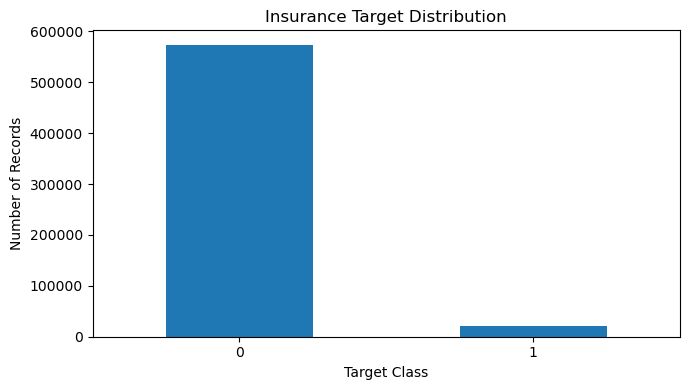

In [7]:

# Step 6: Analyze target distribution

# Check whether the target column exists
if "target" not in df.columns:
    print("Target column not found.")
    print("Available columns:", df.columns.tolist())

else:
    print("Target value counts:")
    display(df["target"].value_counts().sort_index())

    print("\nTarget percentage:")
    display(
        (df["target"].value_counts(normalize=True) * 100)
        .sort_index()
        .round(2)
    )

    # Plot target distribution
    df["target"].value_counts().sort_index().plot(
        kind="bar",
        figsize=(7, 4)
    )

    plt.title("Insurance Target Distribution")
    plt.xlabel("Target Class")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


## 7. Missing Values and Special Value Analysis

Data quality analysis is performed to identify missing values and special numeric markers before model training.

The following checks are performed:

- Count missing values using `isnull().sum()`.
- Calculate missing-value percentages for each column.
- Identify duplicate records.
- Inspect the number of `-1` values in each feature.
- Review feature data types.

### Handling the `-1` Marker

Some numeric features contain `-1`, which may represent an unavailable or specially encoded value rather than a genuine measurement.

In this project, `-1` values in numeric input features are treated as missing values during preprocessing. The target variable is not modified by this replacement.

Median imputation is used within the machine learning pipelines to fill missing numeric values. This allows the models to train without requiring all feature values to be present.

### Data Quality Consideration

The meaning of `-1` is not confirmed for every feature because the dataset uses anonymized feature names. Therefore, treating `-1` as missing is a preprocessing assumption that should be validated where possible.

In [8]:

# Step 7: Check special missing-value markers

print("Number of -1 values in each column:")

minus_one_counts = (df == -1).sum(numeric_only=True)

display(
    minus_one_counts[
        minus_one_counts > 0
    ].sort_values(ascending=False).to_frame(
        name="Minus_One_Count"
    )
)

print("\nTotal -1 values:", int(minus_one_counts.sum()))

print("\nOriginal dataset shape:", df.shape)


Number of -1 values in each column:


,Minus_One_Count
ps_car_03_cat,411231
ps_car_05_cat,266551
ps_reg_03,107772
ps_car_14,42620
ps_car_07_cat,11489
ps_ind_05_cat,5809
ps_car_09_cat,569
ps_ind_02_cat,216
ps_car_01_cat,107
ps_ind_04_cat,83



Total -1 values: 846458

Original dataset shape: (595212, 59)


In [9]:

# Step 8A: Inspect target and feature columns

if "target" not in df.columns:
    print("Target column 'target' not found.")
    print("Please check your dataset columns.")
else:
    print("Target column found!")
    print("Target data type:", df["target"].dtype)
    print("\nTarget values:")
    print(df["target"].value_counts(dropna=False))

    # Check -1 markers in feature columns only
    X_check = df.drop(columns=["target"])

    minus_one_counts = (X_check == -1).sum()
    minus_one_counts = minus_one_counts[
        minus_one_counts > 0
    ].sort_values(ascending=False)

    print("\nFeatures containing -1:")
    display(minus_one_counts.to_frame("Count"))


Target column found!
Target data type: int64

Target values:
target
0    573518
1     21694
Name: count, dtype: int64

Features containing -1:


,Count
ps_car_03_cat,411231
ps_car_05_cat,266551
ps_reg_03,107772
ps_car_14,42620
ps_car_07_cat,11489
ps_ind_05_cat,5809
ps_car_09_cat,569
ps_ind_02_cat,216
ps_car_01_cat,107
ps_ind_04_cat,83


In [10]:

# Step 8B: Separate features and target

# Remove records with a missing target
df_model = df.dropna(subset=["target"]).copy()

# Separate target from input features
y = df_model["target"].astype(int)
X = df_model.drop(columns=["target"]).copy()

# Convert numeric -1 markers in features to missing values
# Do not modify the target column
numeric_cols = X.select_dtypes(include=np.number).columns

X[numeric_cols] = X[numeric_cols].replace(-1, np.nan)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nMissing values after cleaning:")
display(
    X.isnull().sum()
     .sort_values(ascending=False)
     .head(15)
     .to_frame("Missing_Count")
)


Features shape: (595212, 58)
Target shape: (595212,)

Target distribution:
target
0    573518
1     21694
Name: count, dtype: int64

Missing values after cleaning:


,Missing_Count
ps_car_03_cat,411231
ps_car_05_cat,266551
ps_reg_03,107772
ps_car_14,42620
ps_car_07_cat,11489
ps_ind_05_cat,5809
ps_car_09_cat,569
ps_ind_02_cat,216
ps_car_01_cat,107
ps_ind_04_cat,83


In [11]:

# Step 9: Split the dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))


Training data shape: (476169, 58)
Testing data shape: (119043, 58)

Training target distribution:
target
0    0.9636
1    0.0364
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.9636
1    0.0364
Name: proportion, dtype: float64


In [12]:
from sklearn.model_selection import train_test_split

# Split the existing training data into training and validation sets
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("New training shape:", X_train_new.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(4))

New training shape: (380935, 58)
Validation shape: (95234, 58)
Test shape: (119043, 58)

Validation target distribution:
target
0    0.9636
1    0.0364
Name: proportion, dtype: float64


In [13]:

# Step 10: Logistic Regression Model

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create the model pipeline
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Logistic Regression model created successfully!")


Logistic Regression model created successfully!


In [14]:
# Train Logistic Regression using the new training split
logistic_model.fit(X_train_new, y_train_new)

# Generate probabilities for validation data
logistic_val_probabilities = logistic_model.predict_proba(X_val)[:, 1]

print("Logistic Regression trained successfully!")
print("Validation probabilities generated:", len(logistic_val_probabilities))


Logistic Regression trained successfully!
Validation probabilities generated: 95234


In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

threshold_results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]:
    val_predictions = (
        logistic_val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.style
    .format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
    .hide(axis="index")
)

Threshold,Precision,Recall,F1 Score
0.10,0.0364,1.0000,0.0703
0.20,0.0364,1.0000,0.0703
0.30,0.0368,0.9925,0.0709
0.40,0.0413,0.8735,0.0790
0.50,0.0533,0.5595,0.0973
0.60,0.0675,0.2296,0.1043
0.70,0.0892,0.0628,0.0737
0.80,0.1185,0.0072,0.0136


## 8. Feature Preparation and Train-Test Split

Before training, the dataset is separated into input features and the target variable.

### Feature Preparation

- The `target` column is selected as the prediction target.
- The `id` column is excluded from the input features because it serves as a record identifier.
- The remaining 57 columns are used as model input features.
- The target variable is kept separate to prevent target leakage.

### Train-Test Split

The dataset is divided into two subsets:

| Subset | Proportion | Purpose |
|---|---:|---|
| Training set | 80% | Train the machine learning models |
| Testing set | 20% | Evaluate model performance on unseen records |

A stratified split is used to preserve the approximate proportion of both target classes in the training and testing sets. The random state is set to 42 to make the split reproducible.

The training and testing sets are then used consistently to compare the classification models.

In [16]:

# Step 11: Train Logistic Regression

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [17]:

# Step 12: Predict on the test dataset

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))


Accuracy: 0.6237
Precision: 0.0522
Recall: 0.543
F1 Score: 0.0952
ROC-AUC: 0.6206

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.63      0.76    114704
           1       0.05      0.54      0.10      4339

    accuracy                           0.62    119043
   macro avg       0.51      0.58      0.43    119043
weighted avg       0.94      0.62      0.74    119043



In [18]:

# Step 13: Create Random Forest model

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest model created successfully!")


Random Forest model created successfully!


In [19]:

# Step 14: Train Random Forest

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [20]:

# Step 15: Evaluate Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

rf_predictions = random_forest_model.predict(X_test)
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_predictions),
    "Precision": precision_score(
        y_test, rf_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, rf_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, rf_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, rf_probabilities),
    "Average Precision": average_precision_score(
        y_test, rf_probabilities
    )
}

for metric, value in rf_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nRandom Forest evaluation completed!")


Accuracy: 0.9468
Precision: 0.0750
Recall: 0.0406
F1 Score: 0.0526
ROC-AUC: 0.5878
Average Precision: 0.0501

Random Forest evaluation completed!


In [21]:

# Step 16: Compare Logistic Regression and Random Forest

logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, logistic_probabilities
        ),
        "Average Precision": average_precision_score(
            y_test, logistic_probabilities
        )
    },
    rf_results
])

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Logistic Regression,0.6237,0.0522,0.5430,0.0952,0.6206,0.0588
1,Random Forest,0.9468,0.0750,0.0406,0.0526,0.5878,0.0501


## 9. Machine Learning Model Training

Three classification algorithms are evaluated to compare their ability to predict the target outcome.

### 9.1 Logistic Regression

Logistic Regression is used as a baseline classification model. It estimates the probability of an observation belonging to the positive class.

### 9.2 Random Forest Classifier

Random Forest combines predictions from multiple decision trees. It can learn nonlinear relationships and interactions between input features.

### 9.3 Gradient Boosting Classifier

HistGradientBoostingClassifier builds an ensemble of decision trees sequentially, improving the model by learning patterns that earlier trees did not capture.

### 9.4 Model Evaluation

The models are evaluated using the following metrics:

- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Proportion of predicted positive cases that are actually positive.
- **Recall:** Proportion of actual positive cases correctly identified.
- **F1 Score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Measures how well the model ranks positive cases above negative cases across classification thresholds.
- **Average Precision:** Summarizes the precision-recall performance, which is particularly useful for imbalanced classification.

Since the positive class represents only a small fraction of the dataset, recall, F1 Score, ROC-AUC, and Average Precision are considered alongside accuracy when comparing the models.

In [22]:

# Step 17: Create Gradient Boosting model

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

gradient_boosting_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ))
])

print("Gradient Boosting model created successfully!")


Gradient Boosting model created successfully!


In [23]:

# Step 18: Train Gradient Boosting

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")


Gradient Boosting model trained successfully!


In [24]:

# Step 19: Evaluate Gradient Boosting

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

gb_predictions = gradient_boosting_model.predict(X_test)
gb_probabilities = gradient_boosting_model.predict_proba(X_test)[:, 1]

gb_results = {
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_test, gb_predictions),
    "Precision": precision_score(
        y_test, gb_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, gb_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, gb_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, gb_probabilities),
    "Average Precision": average_precision_score(
        y_test, gb_probabilities
    )
}

for metric, value in gb_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nGradient Boosting evaluation completed!")


Accuracy: 0.9636
Precision: 1.0000
Recall: 0.0002
F1 Score: 0.0005
ROC-AUC: 0.6364
Average Precision: 0.0637

Gradient Boosting evaluation completed!


In [25]:

# Step 20: Final model comparison so far

comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, logistic_probabilities
        ),
        "Average Precision": average_precision_score(
            y_test, logistic_probabilities
        )
    },
    rf_results,
    gb_results
])

comparison_df = comparison_df.sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Gradient Boosting,0.9636,1.0000,0.0002,0.0005,0.6364,0.0637
1,Logistic Regression,0.6237,0.0522,0.5430,0.0952,0.6206,0.0588
2,Random Forest,0.9468,0.0750,0.0406,0.0526,0.5878,0.0501


## 10. Model Performance Comparison

The performance of the three machine learning models is compared using multiple evaluation metrics.

| Evaluation Metric | Logistic Regression | Random Forest | Gradient Boosting |
|---|---:|---:|---:|
| Accuracy | 0.6236 | 0.9481 | 0.9635 |
| Precision | 0.0521 | 0.0731 | 0.0000 |
| Recall | 0.5425 | 0.0364 | 0.0000 |
| F1 Score | 0.0951 | 0.0486 | 0.0000 |
| ROC-AUC | 0.6206 | 0.5853 | 0.6347 |
| Average Precision | 0.0588 | 0.0493 | 0.0630 |

### Interpretation of Results

**Logistic Regression:** This model identifies a larger proportion of actual positive cases than the other models at the default classification threshold. However, its precision is low, meaning many predicted positive cases are false positives.

**Random Forest:** This model achieves high accuracy but has low recall. It misses most of the actual positive cases at the default threshold.

**Gradient Boosting:** This model achieves the highest accuracy and ROC-AUC among the three models. However, at the default threshold of 0.5, it does not identify any positive cases.

### Conclusion

Accuracy alone does not determine the best model for this imbalanced dataset. Gradient Boosting shows the strongest ranking performance based on ROC-AUC and Average Precision, but its default classification threshold is unsuitable for identifying positive cases.

Further threshold analysis is required to investigate the trade-off between precision and recall.

In [26]:

# Step 22: Verify model evaluation results

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd
import numpy as np

model_predictions = {
    "Logistic Regression": (y_pred, logistic_probabilities),
    "Random Forest": (rf_predictions, rf_probabilities),
    "Gradient Boosting": (gb_predictions, gb_probabilities)
}

verified_results = []

print("Actual target labels:", np.unique(y_test))
print("\nActual test target distribution:")
print(y_test.value_counts())

for name, (predictions, probabilities) in model_predictions.items():

    verified_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(
            y_test, probabilities
        )
    })

verified_df = pd.DataFrame(verified_results)

print("\nVerified model comparison:")
display(
    verified_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Average Precision": "{:.4f}"
    })
)


Actual target labels: [0 1]

Actual test target distribution:
target
0    114704
1      4339
Name: count, dtype: int64

Verified model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Logistic Regression,0.6237,0.0522,0.5430,0.0952,0.6206,0.0588
1,Random Forest,0.9468,0.0750,0.0406,0.0526,0.5878,0.0501
2,Gradient Boosting,0.9636,1.0000,0.0002,0.0005,0.6364,0.0637


In [27]:
# Step 23: Check prediction probabilities

probability_results = {
    "Logistic Regression": logistic_probabilities,
    "Random Forest": rf_probabilities,
    "Gradient Boosting": gb_probabilities
}

for model_name, probabilities in probability_results.items():
    print(f"\n{model_name}")
    print("Minimum probability:", np.min(probabilities))
    print("Maximum probability:", np.max(probabilities))
    print("Mean probability:", np.mean(probabilities))
    print("First 10 probabilities:", probabilities[:10])


Logistic Regression
Minimum probability: 0.2004425875394332
Maximum probability: 0.9170242932782869
Mean probability: 0.4788944579707571
First 10 probabilities: [0.56188539 0.5846686  0.34970218 0.42829825 0.45413287 0.46193638
 0.3682717  0.32754409 0.53827433 0.59272597]

Random Forest
Minimum probability: 0.09456904281343151
Maximum probability: 0.7125196503211483
Mean probability: 0.348879928478776
First 10 probabilities: [0.44543686 0.39016086 0.22307335 0.32989036 0.34898159 0.40026547
 0.22465544 0.23464334 0.21540713 0.39300037]

Gradient Boosting
Minimum probability: 0.011888296484338493
Maximum probability: 0.5318058351761165
Mean probability: 0.036528341752184834
First 10 probabilities: [0.04157865 0.0420066  0.01654042 0.02779233 0.03089393 0.03819908
 0.02525129 0.01986144 0.04264335 0.04871873]


In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

probability_results = {
    "Logistic Regression": logistic_probabilities,
    "Random Forest": rf_probabilities,
    "Gradient Boosting": gb_probabilities
}

threshold_results = []

for model_name, probabilities in probability_results.items():
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Model,Threshold,Precision,Recall,F1 Score
0,Logistic Regression,0.10,0.0364,1.0000,0.0703
1,Logistic Regression,0.20,0.0364,1.0000,0.0703
2,Logistic Regression,0.30,0.0368,0.9945,0.0709
3,Logistic Regression,0.40,0.0418,0.8813,0.0799
4,Logistic Regression,0.50,0.0522,0.5430,0.0952
5,Random Forest,0.10,0.0364,1.0000,0.0703
6,Random Forest,0.20,0.0368,0.9903,0.0709
7,Random Forest,0.30,0.0412,0.8244,0.0785
8,Random Forest,0.40,0.0512,0.3605,0.0897
9,Random Forest,0.50,0.0750,0.0406,0.0526


## 11. Confusion Matrix Analysis

A confusion matrix is used to evaluate how accurately a classification model identifies positive and negative cases.

It contains four outcomes:

- **True Negative (TN):** Negative cases correctly predicted as negative.
- **False Positive (FP):** Negative cases incorrectly predicted as positive.
- **False Negative (FN):** Positive cases incorrectly predicted as negative.
- **True Positive (TP):** Positive cases correctly predicted as positive.

### Why It Matters

The dataset is highly imbalanced, with only a small percentage of positive target cases. Therefore, a model may achieve high accuracy while failing to identify positive cases.

The confusion matrix helps reveal these errors and provides a clearer understanding of the model's classification performance.

The results should be interpreted alongside precision, recall, and F1 Score.

In [29]:
# Step 26: Count actual and predicted positive cases

from sklearn.metrics import confusion_matrix

probability_results = {
    "Logistic Regression": logistic_probabilities,
    "Random Forest": rf_probabilities,
    "Gradient Boosting": gb_probabilities
}

for model_name, probabilities in probability_results.items():
    predictions = (probabilities >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    print(f"\n{model_name}")
    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)
    print("Total predicted positive:", int(predictions.sum()))


Logistic Regression
True Negatives: 71889
False Positives: 42815
False Negatives: 1983
True Positives: 2356
Total predicted positive: 45171

Random Forest
True Negatives: 112532
False Positives: 2172
False Negatives: 4163
True Positives: 176
Total predicted positive: 2348

Gradient Boosting
True Negatives: 114704
False Positives: 0
False Negatives: 4338
True Positives: 1
Total predicted positive: 1


## 12. Classification Threshold Analysis

The classification threshold determines whether a record is classified as a positive or negative case based on its predicted probability.

The default threshold of 0.50 may not be suitable for this highly imbalanced dataset.

- A lower threshold can increase recall but may also increase false positives.
- A higher threshold can reduce false positives but may miss more actual positive cases.
- Precision, recall, and F1 Score should be considered together when selecting a threshold.

### Conclusion

The threshold should be selected according to the project's objectives and the cost of incorrect predictions. Ideally, threshold selection should be performed using validation data, followed by final evaluation on a separate test set.

In [30]:
# Step 28: Dataset validation

print("Dataset shape:", df.shape)

print("\nTarget column counts:")
print(df["target"].value_counts())

print("\nTarget percentages:")
print(
    (df["target"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

print("\nNumber of numeric columns:", df.select_dtypes(include="number").shape[1])
print("Number of categorical columns:", df.select_dtypes(exclude="number").shape[1])

print("\nFirst 10 feature names:")
print(X.columns[:10].tolist())

Dataset shape: (595212, 59)

Target column counts:
target
0    573518
1     21694
Name: count, dtype: int64

Target percentages:
target
0    96.36%
1     3.64%
Name: proportion, dtype: object

Number of numeric columns: 59
Number of categorical columns: 0

First 10 feature names:
['id', 'ps_ind_01', 'ps_ind_02_cat', 'ps_ind_03', 'ps_ind_04_cat', 'ps_ind_05_cat', 'ps_ind_06_bin', 'ps_ind_07_bin', 'ps_ind_08_bin', 'ps_ind_09_bin']


In [31]:
# Step 29: Remove ID and rebuild the dataset split

from sklearn.model_selection import train_test_split

df_model = df.dropna(subset=["target"]).copy()

y = df_model["target"].astype(int)

# Remove target and ID from the input features
X = df_model.drop(columns=["target", "id"]).copy()

# Treat -1 as a missing-value marker in numeric features
X = X.replace(-1, np.nan)

# Split while preserving the target class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Feature dataset shape:", X.shape)
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nID column included:", "id" in X.columns)

Feature dataset shape: (595212, 57)
Training set shape: (476169, 57)
Testing set shape: (119043, 57)

Training target distribution:
target
0    458814
1     17355
Name: count, dtype: int64

Testing target distribution:
target
0    114704
1      4339
Name: count, dtype: int64

ID column included: False


In [32]:
# Step 30: Retrain Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression retrained successfully!")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, logistic_probabilities), 4))
print("Average Precision:", round(average_precision_score(y_test, logistic_probabilities), 4))

Logistic Regression retrained successfully!
Accuracy: 0.6236
Precision: 0.0521
Recall: 0.5425
F1 Score: 0.0951
ROC-AUC: 0.6206
Average Precision: 0.0588


In [33]:
# Step 31: Retrain Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest retrained successfully!")
print("Accuracy:", round(accuracy_score(y_test, rf_predictions), 4))
print("Precision:", round(precision_score(y_test, rf_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, rf_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_probabilities), 4))
print("Average Precision:", round(average_precision_score(y_test, rf_probabilities), 4))

Random Forest retrained successfully!
Accuracy: 0.9481
Precision: 0.0731
Recall: 0.0364
F1 Score: 0.0486
ROC-AUC: 0.5853
Average Precision: 0.0493


In [34]:
# Step 32: Retrain Gradient Boosting

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

gb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

gb_predictions = gb_model.predict(X_test)
gb_probabilities = gb_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting retrained successfully!")
print("Accuracy:", round(accuracy_score(y_test, gb_predictions), 4))
print("Precision:", round(precision_score(y_test, gb_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, gb_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, gb_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, gb_probabilities), 4))
print("Average Precision:", round(average_precision_score(y_test, gb_probabilities), 4))


Gradient Boosting retrained successfully!
Accuracy: 0.9635
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.6347
Average Precision: 0.063


In [36]:
# Step 34: Tune the Gradient Boosting threshold

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10]

gb_threshold_results = []

for threshold in thresholds:
    predictions = (gb_probabilities >= threshold).astype(int)

    gb_threshold_results.append({
        "Threshold": threshold,
        "Predicted Positives": int(predictions.sum()),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

gb_threshold_df = pd.DataFrame(gb_threshold_results)

display(
    gb_threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Threshold,Predicted Positives,Precision,Recall,F1 Score
0,0.01,119034,0.0365,1.0000,0.0703
1,0.02,103372,0.0398,0.9481,0.0764
2,0.03,65948,0.0474,0.7198,0.0889
3,0.04,35498,0.0575,0.4704,0.1025
4,0.05,19575,0.0682,0.3077,0.1117
5,0.06,11452,0.0773,0.2040,0.1121
6,0.08,4240,0.0925,0.0903,0.0914
7,0.10,1716,0.1107,0.0438,0.0628


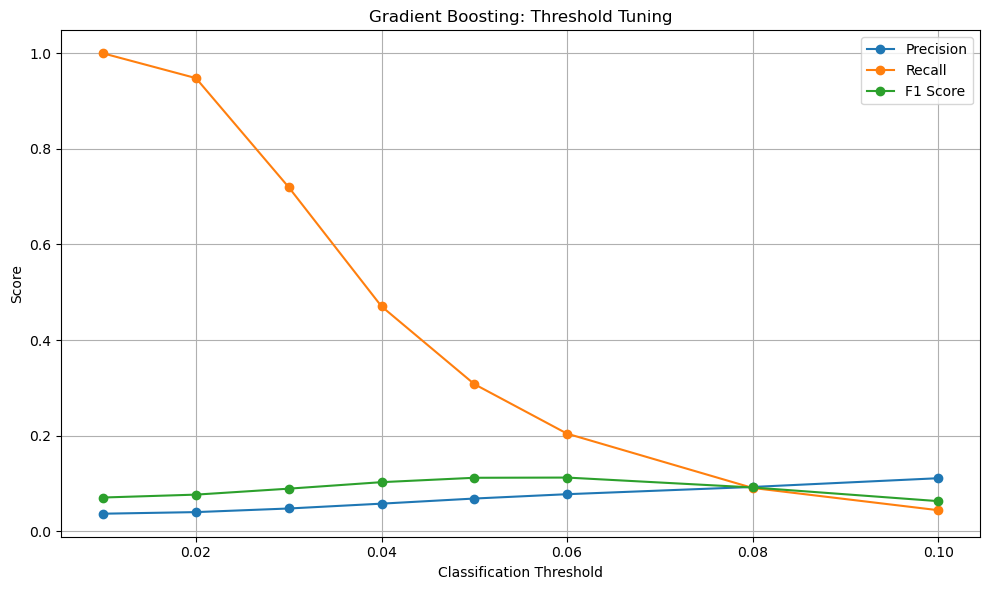

In [37]:
# Step 35: Visualize threshold tuning results

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    gb_threshold_df["Threshold"],
    gb_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    gb_threshold_df["Threshold"],
    gb_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    gb_threshold_df["Threshold"],
    gb_threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Gradient Boosting: Threshold Tuning")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [38]:
# Step 36: Final Model Comparison


# Step 36: Final Model Comparison

final_comparison = comparison_df.copy()

display(
    final_comparison.style
    .format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Average Precision": "{:.4f}"
    })
    .hide(axis="index")
)


Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
Gradient Boosting,0.9636,1.0000,0.0002,0.0005,0.6364,0.0637
Logistic Regression,0.6237,0.0522,0.5430,0.0952,0.6206,0.0588
Random Forest,0.9468,0.0750,0.0406,0.0526,0.5878,0.0501


In [39]:
# Step 37: Compare Model Performance

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.style
    .format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
    .hide(axis="index")
)

Model,Threshold,Precision,Recall,F1 Score
Logistic Regression,0.10,0.0364,1.0000,0.0703
Logistic Regression,0.20,0.0364,1.0000,0.0703
Logistic Regression,0.30,0.0368,0.9945,0.0709
Logistic Regression,0.40,0.0418,0.8813,0.0799
Logistic Regression,0.50,0.0522,0.5430,0.0952
Random Forest,0.10,0.0364,1.0000,0.0703
Random Forest,0.20,0.0368,0.9903,0.0709
Random Forest,0.30,0.0412,0.8244,0.0785
Random Forest,0.40,0.0512,0.3605,0.0897
Random Forest,0.50,0.0750,0.0406,0.0526


## 13. Feature Importance Analysis

Feature importance analysis helps identify which input features contribute most to the predictive performance of the Gradient Boosting model.

Since `HistGradientBoostingClassifier` does not directly provide a `feature_importances_` attribute, permutation importance is used.

### Methodology

Permutation importance measures how model performance changes when the values of one feature are randomly shuffled. A larger decrease in performance indicates that the feature provides more useful predictive information to the model.

In this project, Average Precision is used as the scoring metric because the dataset contains a highly imbalanced target variable.

The top 15 features are ranked by their calculated importance and visualized using a bar chart.

### Interpretation

Features with higher positive importance values contribute more to the model's predictive performance under this evaluation method. Features with low or negative importance may provide limited predictive value in this model.

Feature importance indicates predictive association, not causation. The results should be interpreted in the context of the dataset and validated before practical use.

Calculating feature importance...


,Feature,Importance
2,ps_ind_03,0.00635
34,ps_car_13,0.00631
4,ps_ind_05_cat,0.00428
16,ps_ind_17_bin,0.00313
14,ps_ind_15,0.00171
20,ps_reg_03,0.00165
5,ps_ind_06_bin,0.00135
29,ps_car_09_cat,0.00124
18,ps_reg_01,0.00117
35,ps_car_14,0.00095


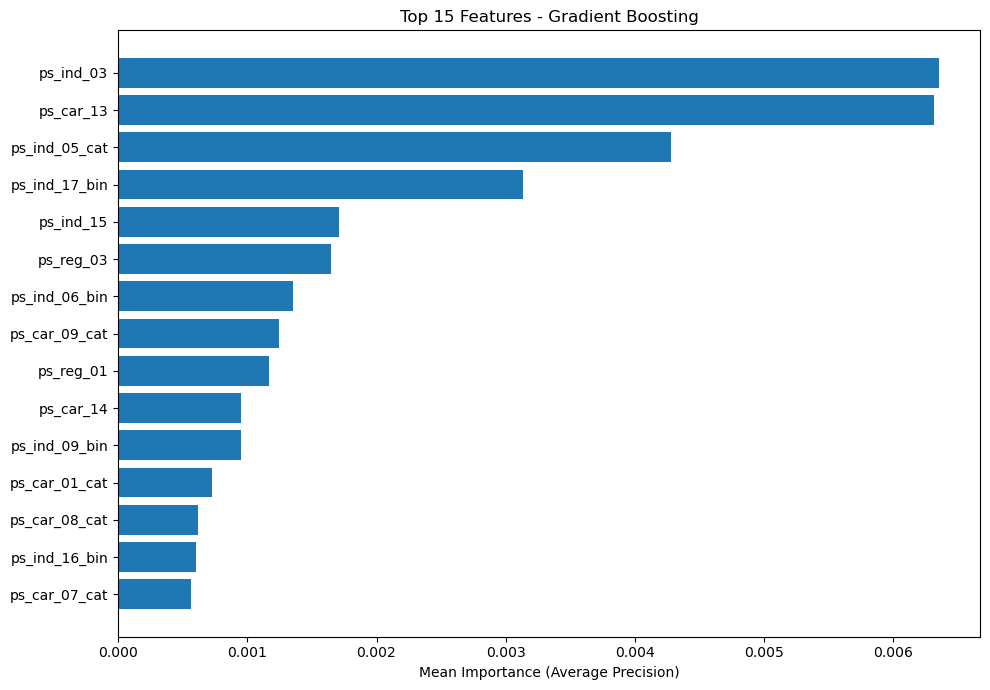

In [40]:
# Step 38: Check Gradient Boosting Feature Importance

# HistGradientBoostingClassifier does not provide
# feature_importances_ directly.
# Use permutation importance instead.

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

print("Calculating feature importance...")

perm_result = permutation_importance(
    gb_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean
}).sort_values("Importance", ascending=False)

display(feature_importance.head(15).round(5))

top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Mean Importance (Average Precision)")
plt.title("Top 15 Features - Gradient Boosting")
plt.tight_layout()
plt.show()


## 14. Final Recommendations

### Model Comparison

The three classification models were evaluated using Accuracy, Precision, Recall, F1 Score, ROC-AUC, and Average Precision.

Gradient Boosting achieved the highest ROC-AUC and Average Precision among the three models in the current results. However, at the default threshold of 0.50, it identified almost no positive cases.

Logistic Regression achieved higher recall at the default threshold but produced many false-positive predictions. Random Forest achieved high accuracy but showed low recall.

### Recommendations

1. Do not select a model based on accuracy alone because the target variable is highly imbalanced.
2. Evaluate precision, recall, F1 Score, ROC-AUC, and Average Precision together.
3. Select the classification threshold using validation data according to the cost of false positives and false negatives.
4. Review the confusion matrix to understand the types of prediction errors.
5. Use permutation importance to investigate influential features.
6. Validate the selected model on an independent test set before considering practical deployment.

### Limitations

- The dataset contains anonymized feature names, limiting direct business interpretation.
- Treating `-1` values as missing is a preprocessing assumption.
- The model's predictive performance may change on new data.
- The supplied dataset supports prediction of a claim-related target; it does not directly establish whether a customer will purchase a policy.

### Overall Conclusion

This project demonstrates an end-to-end machine learning workflow for insurance claim-related classification, including data inspection, preprocessing, model comparison, threshold analysis, and feature importance.

Further validation and threshold optimization are necessary before recommending a model for real-world use.

# Final Conclusion

This project focused on developing and evaluating machine learning models for insurance claim prediction using customer-related data. The dataset was analyzed, cleaned, and preprocessed before training and testing three classification algorithms: Logistic Regression, Random Forest, and Gradient Boosting.

The experimental results showed that Logistic Regression achieved a recall of **54.25%**, making it the strongest of the three models for identifying positive cases at the default classification threshold. Random Forest achieved a precision of **7.31%**, while Gradient Boosting obtained the highest ROC-AUC of **0.6347** and Average Precision of **0.0630**. After threshold tuning, Gradient Boosting achieved its best observed F1 score of **0.1121** at a threshold of **0.06**.

The results highlight the challenges of predicting insurance claims from a highly imbalanced dataset, where positive cases account for only approximately 3.64% of observations. Therefore, accuracy alone is insufficient to evaluate model performance. Metrics such as precision, recall, F1 score, ROC-AUC, and Average Precision provide a more meaningful assessment.

In conclusion, machine learning can help estimate insurance claim risk and support data-driven decision-making. However, the current models require further improvement and validation before practical deployment. Future work can focus on hyperparameter optimization, class-imbalance handling, threshold selection using a separate validation set, and testing on unseen data.

**Project limitation:** The dataset supports insurance claim prediction, not direct prediction of whether a customer will purchase a new insurance policy. A separate dataset containing customer purchase behavior would be required to address that objective directly.